# Vertical Quantum Federated Learning — a reproduction, with controls and a photonic adaptation

This notebook walks through the reproduction of *Vertical Quantum Federated Learning* (R. Ballester, C. Blum, J. Cerquides, L. Artiles, ICEA '25, [doi:10.1145/3803817.3803821](https://doi.org/10.1145/3803817.3803821)). It sets out the paper's claim, rebuilds the model from small verifiable pieces, runs reduced experiments live, and then loads the full paper-scale results to test the claim against controls, a parameter-matched classical baseline and a MerLin photonic adaptation.

**How to read it.**
- **Live and stored results.** Cells marked *live* run in seconds to a few minutes on a laptop CPU. The paper-scale runs took 16–35 minutes each, so they are loaded from durable records in `results/`, which are generated from validated, logged runs (see `LOG.md`).
- **Labels.** Every live result is labelled `reduced`, so it never stands in for the full reproduction.

## 1. Problem statement and paper claim

**Setting: vertical (feature-partitioned) federated learning.**
- Several parties hold *different features of the same samples*.
- Here, each client holds a disjoint random subset of the 256 pixels of each Semeion digit image.
- Each client runs its own model on its own pixels and sends a short message (8 numbers) to a server, which holds the labels.
- The server combines the messages and predicts the digit.
- Training is end to end: the server sends back the gradient of the loss with respect to each message.

**The paper's proposal.** It makes every party a **fully quantum model**: an 8-qubit data re-uploading circuit, with no classical layers. Its claims:

| ID | Claim | Experiment |
|---|---|---|
| C1 | 8 clients on all pixels reach **over 94%** test accuracy on 10 classes | E1 (Fig. 2) |
| C2 | 8 clients beat a single client with the same per-model parameter budget | E1 vs E2 (Fig. 2) |
| C3 | The gain comes from *distinct* features, not from the server's wider input | E3, one pixel slice duplicated over 8 clients (Fig. 3) |
| C4 | Half the pixels is only slightly worse (about 90%) | E4, 4 slices each duplicated twice (Fig. 3) |
| C5-C7 | Robust to the random feature assignment; privacy preserved; suited to NISQ devices | argued, not measured |

**Falsifiable research question.** *Does an 8-client VQFL model reach the paper's accuracy, and is its advantage over one client due to distinct features rather than server width, and is it any better than a classical vertical-FL model with the same number of trainable parameters?*

**What would weaken the claims:**
- C1: final-epoch accuracy clearly below 94% under the paper's protocol.
- C2 and C3: E3 matching E1. That would mean the server's input width, not the extra features, drives the gain.
- Any reading of VQFL as useful: a parameter-matched classical vertical-FL model doing as well or better, and showing the same pattern.

In [1]:
# Setup: paths, imports and the scientifically important constants.
import json
import math
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

PROJECT_DIR = Path.cwd()
REPO_ROOT = PROJECT_DIR.parent.parent
for path in (REPO_ROOT, PROJECT_DIR):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

RESULTS = PROJECT_DIR / "results"
DATA_ROOT = REPO_ROOT / "data"
AUTHORS_SETTING_1 = DATA_ROOT / "vertical_qfl/vqfl_authors_assets/VQFL/exps/Setting_1"
PERMUTATION_SEEDS = [42, 43, 44, 45, 46]  # the paper's 5 random feature distributions
COLORS = {"E1": "#1b6ca8", "E2": "#b5651d", "E3": "#6b8e23", "E4": "#8e44ad"}
torch.set_num_threads(4)
print("torch", torch.__version__, "| project", PROJECT_DIR.name)

torch 2.12.1 | project vertical_qfl


## 2. Data, splits, metrics and evaluation protocol

**Data.** The Semeion Handwritten Digit set (UCI) has 1593 binary 16×16 images in 10 classes, about 160 per class. Following the authors' code:

1. Each pixel becomes a rotation angle: 0 or π/4.
2. The 256 pixel columns are shuffled by a seeded permutation. This is the paper's "random feature distribution", with permutation seeds 42–46.
3. Client *k* receives columns 32k to 32k+31 of the shuffled image.
4. A **stratified 80/20 split** (`random_state = 42`) gives 1274 training images and 319 test images.

**Metric and protocol:**
- **Metric:** test accuracy at the **last epoch** (30 epochs, Adam, learning rate 0.002, batch 32), averaged over the 5 feature distributions, with the sample standard deviation.
- **No validation split.** The paper has none, so any "best epoch" number would be selected on the test set. It is shown only as such.
- **Resolution:** one test image is 0.31 points, and one run's binomial standard error is about 1.4 points at 93%.
- **Tuning added in this reproduction:** where hyperparameters had to be chosen (the photonic and classical models), they were selected on a validation split carved out of the training set. **The test set was never used for selection.**

In [2]:
# Live: build the split exactly as the runner does, and check it against the authors' saved tensors.
from lib.data import build_splits

config = json.loads((PROJECT_DIR / "configs/e1_8clients_original.json").read_text())
config["data_root"] = str(DATA_ROOT)
splits = build_splits(config)
(train_x, train_y), (test_x, test_y) = splits["train"], splits["test"]
print("train", tuple(train_x.shape), "| test", tuple(test_x.shape), "| pixel values", sorted(train_x.unique().tolist()))
print("test images per class:", torch.bincount(test_y).tolist())

if (AUTHORS_SETTING_1 / "data_tensors.pt").exists():
    reference = torch.load(AUTHORS_SETTING_1 / "data_tensors.pt", weights_only=True, map_location="cpu")
    same = torch.equal(train_x, reference["data_tr"]) and torch.equal(test_y, reference["label_te"])
    print("identical to the authors' Setting_1 split:", same)
else:
    print("authors' assets not downloaded; split identity check skipped")

train (1274, 256) | test (319, 256) | pixel values [0.0, 0.7853981633974483]
test images per class: [32, 32, 32, 32, 32, 32, 32, 32, 31, 32]
identical to the authors' Setting_1 split: True


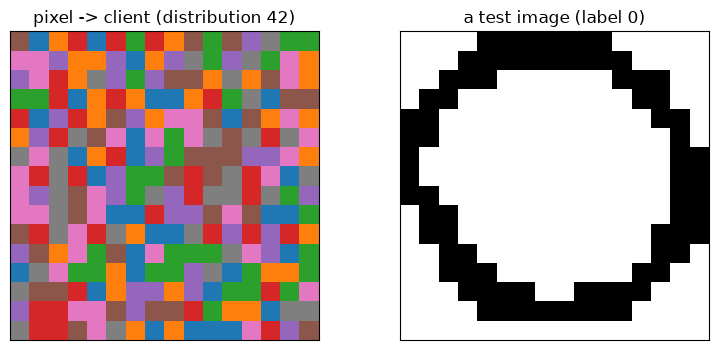

In [3]:
# Live: what one client "sees". Each colour is one of the 8 clients; the assignment is random.
torch.manual_seed(42)
permutation = torch.randperm(256)  # same call as lib.data.build_splits for permutation seed 42
owner = torch.empty(256, dtype=torch.long)
owner[permutation] = torch.arange(256) // 32  # shuffled column j goes to client j // 32

fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
axes[0].imshow(owner.reshape(16, 16), cmap="tab10", vmin=0, vmax=9)
axes[0].set_title("pixel -> client (distribution 42)")
axes[1].imshow((test_x[0][torch.argsort(permutation)] > 0).reshape(16, 16), cmap="gray_r")
axes[1].set_title(f"a test image (label {int(test_y[0])})")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**Observation.** Each client gets 32 scattered pixels, not a contiguous patch. **Inference.** No single client can recognise a digit on its own; accuracy must come from combining messages. This is what makes E2 (one client) a meaningful control.

## 3. The model in equations

**Gate circuits.** Every party is the same kind of 8-qubit circuit. Write $R(\boldsymbol\theta_\ell)=\bigotimes_{q} R_Y(\theta_{\ell,q,2})R_X(\theta_{\ell,q,1})$ for one trainable layer and $C$ for the ring of CZ gates. A **block** is

$$B_d(\boldsymbol x) \;=\; C\,E_d(\boldsymbol x)\,\prod_{\ell=1}^{L} \big(C\,R(\boldsymbol\theta_{d,\ell})\big),$$

where $E_d$ encodes 8 input values as single-qubit rotations, alternating between $R_X$ and $R_Y$. Each party applies $D-1=4$ such blocks, so a client encodes $4\times 8 = 32$ pixels, then one last trainable block, and measures:
- **Clients** send $\big(\langle Z_1\rangle,\dots,\langle Z_8\rangle\big)\in[-1,1]^8$.
- **The server** takes the 64 concatenated values, encoding 16 per block, and outputs 10 class scores $\big(\langle Z_1..Z_5\rangle,\langle X_1..X_5\rangle\big)$.

**Size.** With $D=5$ and $L=100$, every party has $5\times100\times2\times8 = 8000$ trainable angles, so the 8-client system has 72,000.

**Training.** One end-to-end backward pass through all circuits gives exactly the paper's split-learning update. The server's gradient $\partial\mathcal L/\partial H$ times each client's Jacobian is the chain rule that the paper exchanges between parties.

## 4. Known-answer sanity checks

The paper's simulator (TorchQuantum 0.1.8) no longer installs cleanly, so `lib/statevector.py` re-implements the few gates needed. Two checks establish that it is right before anything is trained.

1. **Against first principles.** A small client circuit is built gate by gate as explicit 256×256 numpy matrices, and the outputs must agree to numerical precision.
2. **Against the authors' trained model.** Loading their saved 8-client parameters must reproduce their recorded test accuracy. This single check tests the circuit layout, gate conventions, readout and data pipeline at once.

In [4]:
# Live check 1: PyTorch simulator vs. an independent dense numpy implementation (3 blocks x 2 layers).
from lib.model import ReuploadingCircuit

X = np.array([[0, 1], [1, 0]], dtype=complex); Y = np.array([[0, -1j], [1j, 0]]); Z = np.diag([1.0, -1.0]).astype(complex)

def rotation(pauli, angle):
    return np.cos(angle / 2) * np.eye(2) - 1j * np.sin(angle / 2) * pauli

def on_wire(gate, wire, n=8):
    out = np.array([[1.0 + 0j]])
    for w in range(n):
        out = np.kron(out, gate if w == wire else np.eye(2))
    return out

ring = np.diag([(-1) ** sum(((i >> (7 - w)) & 1) * ((i >> (7 - (w + 1) % 8)) & 1) for w in range(8)) for i in range(256)]).astype(complex)

def dense_client(angles, x, n_blocks, depth):
    state = np.zeros(256, dtype=complex); state[0] = 1
    for block in range(n_blocks):
        for layer in range(depth):
            for wire in range(8):
                state = on_wire(rotation(X, angles[block * depth + layer, 0, wire]), wire) @ state
            for wire in range(8):
                state = on_wire(rotation(Y, angles[block * depth + layer, 1, wire]), wire) @ state
            if not (block == n_blocks - 1 and layer == depth - 1):
                state = ring @ state
        if block < n_blocks - 1:
            for wire in range(8):
                state = on_wire(rotation(X if block % 2 == 0 else Y, x[block * 8 + wire]), wire) @ state
            state = ring @ state
    return np.array([np.real(state.conj() @ on_wire(Z, w) @ state) for w in range(8)])

torch.manual_seed(0)
circuit = ReuploadingCircuit("client", n_blocks=3, depth_per_block=2, dtype=torch.float64).double()
x_small = torch.rand(1, 32, dtype=torch.float64) * math.pi / 4
ours = circuit(x_small).detach().numpy()[0]
dense = dense_client(circuit.angles.detach().numpy(), x_small.numpy()[0], 3, 2)
print("max |difference| =", float(np.abs(ours - dense).max()))
assert np.allclose(ours, dense, atol=1e-10)

max |difference| = 2.0122792321330962e-16


In [5]:
# Live check 2: the authors' trained 8-client model, evaluated with this code (float64, about 3 s).
from lib.model import VerticalQuantumFederatedModel

def load_authors_angles(state_dict):
    prefix = "q." if "q.u_layers.0.params" in state_dict else ""
    out = torch.zeros(500, 2, 8, dtype=torch.float64)
    for layer in range(500):
        for kind in range(2):
            for wire in range(8):
                out[layer, kind, wire] = state_dict[f"{prefix}u_layers.{wire + (2 * layer + kind) * 8}.params"].reshape(-1)[0]
    return out

if (AUTHORS_SETTING_1 / "models_tensors.pth").exists():
    checkpoint = torch.load(AUTHORS_SETTING_1 / "models_tensors.pth", weights_only=True, map_location="cpu")
    recorded = json.loads((AUTHORS_SETTING_1 / "exp.json").read_text())["all_test_acc"][-1]
    authors_model = VerticalQuantumFederatedModel(list(range(8)), "server_wide", True, dtype=torch.float64).double()
    for i, client in enumerate(authors_model.clients):
        client.angles.data = load_authors_angles(checkpoint[f"client{i + 1}_model"])
    authors_model.server.angles.data = load_authors_angles(checkpoint["server_model"])
    with torch.no_grad():
        accuracy = (authors_model(reference["data_te"].double()).argmax(1) == reference["label_te"]).double().mean().item()
    print(f"authors' recorded test accuracy {recorded:.4f} | this implementation {accuracy:.4f}")
else:
    print("authors' assets not downloaded; check skipped")

authors' recorded test accuracy 0.9373 | this implementation 0.9373


**Observation.**
- The simulator matches a dense, gate-by-gate implementation to about 1e-16.
- The authors' own trained model, run through this code, gives exactly their recorded accuracy: 0.9373, or 299 of 319 test images.

**Inference.** The circuit layout, gate conventions, readout and data split are those of the paper's code.

**Remaining uncertainty.** Matching their evaluation does not show that *training* from scratch behaves the same way; Section 7 tests that.

**Claim impact.** This validates the components only. It is not a reproduction of any result yet.

## 5. Walking through one forward pass

The cell below builds the paper's 8-client model and checks four things:
- each party holds 8000 trainable angles;
- each client sends 8 bounded numbers;
- the server returns 10 class scores;
- every client receives a gradient.

In [6]:
# Live: shapes, parameter counts and gradient flow of the paper-scale model (one batch of 4 images).
torch.manual_seed(42)
model = VerticalQuantumFederatedModel(list(range(8)), "server_wide", softmax_output=True)
print("trainable angles:", model.trainable_parameter_counts())
batch = test_x[:4].float()
messages = [client(batch[:, 32 * k: 32 * k + 32]) for k, client in enumerate(model.clients)]
print("client 0 message:", messages[0][0].detach().numpy().round(3), "(8 values of <Z>, in [-1, 1])")
scores = model(batch)
print("server output shape:", tuple(scores.shape), "(10 class probabilities; softmax as in the authors' code)")
torch.nn.CrossEntropyLoss()(scores, test_y[:4]).backward()
print("every client receives a gradient:", all(c.angles.grad.abs().sum() > 0 for c in model.clients))

trainable angles: {'client_0': 8000, 'client_1': 8000, 'client_2': 8000, 'client_3': 8000, 'client_4': 8000, 'client_5': 8000, 'client_6': 8000, 'client_7': 8000, 'server': 8000, 'total': 72000}


client 0 message: [-0.047 -0.109  0.122 -0.014  0.014 -0.159  0.045 -0.054] (8 values of <Z>, in [-1, 1])


server output shape: (4, 10) (10 class probabilities; softmax as in the authors' code)


every client receives a gradient: True


## 6. A small live experiment (reduced)

**The test.** Does adding clients help when everything else is fixed? This trains, with the real runner (`lib/runner.py`), a **reduced** gate model. The reduction is $L = 10$ instead of 100 layers per block and 4 epochs instead of 30, on the full data and one feature distribution:
- **E1:** 8 clients;
- **E2:** 1 client;
- **classical E1:** a classical vertical-FL model with the same partitions and the same number of trainable parameters as the reduced E1, introduced fully in Section 8.

**The scope label.** These runs are `reduced` and single-seed. They show the mechanism and the pipeline working, nothing more. The paper-scale numbers are in Section 7.

In [7]:
# Live (about 1-2 min): reduced E1, E2 and a matched classical model through lib.runner.train_and_evaluate.
import contextlib
import copy
import io
import tempfile

from lib import runner
from lib.model_classical import mlp_parameter_count

def run_live(base_config, overrides, label):
    cfg = copy.deepcopy(base_config)
    for section, values in overrides.items():
        cfg[section].update(values) if isinstance(values, dict) else cfg.__setitem__(section, values)
    cfg["dtype"], cfg["seed"], cfg["data_root"] = "float32", 42, str(DATA_ROOT)
    with tempfile.TemporaryDirectory() as tmp, contextlib.redirect_stderr(io.StringIO()):
        run_dir = Path(tmp)
        (run_dir / "config_snapshot.json").write_text(json.dumps(cfg))
        start = time.perf_counter()
        runner.train_and_evaluate(cfg, run_dir)
        metrics = json.loads((run_dir / "metrics.json").read_text())
    print(f"{label:<34} params {metrics['trainable_parameters']['total']:>6}  test acc {metrics['final_test_accuracy']:.3f}  ({time.perf_counter() - start:.0f} s)")
    return metrics

LIVE_EPOCHS, LIVE_DEPTH = 4, 10
live = {}
live["E1 gate (8 clients, reduced)"] = run_live(config, {"model": {"depth_per_block": LIVE_DEPTH}, "training": {"epochs": LIVE_EPOCHS}}, "E1 gate (8 clients, reduced)")
live["E2 gate (1 client, reduced)"] = run_live(config, {"model": {"depth_per_block": LIVE_DEPTH, "client_slices": [0], "server_encoding": "server_narrow"}, "training": {"epochs": LIVE_EPOCHS}}, "E2 gate (1 client, reduced)")
# Classical model with the same number of trainable parameters as the reduced E1 (5 x 10 x 2 x 8 = 800 per party).
hidden_client = min(range(1, 200), key=lambda h: abs(mlp_parameter_count(32, h, 8) - 800))
hidden_server = min(range(1, 200), key=lambda h: abs(mlp_parameter_count(64, h, 10) - 800))
live["E1 classical (matched, reduced)"] = run_live(
    config,
    {"model": {"backend": "classical", "architecture": "vertical", "client_slices": list(range(8)), "server_encoding": "server_wide",
               "client_hidden": hidden_client, "server_hidden": hidden_server},
     "training": {"epochs": LIVE_EPOCHS}}, "E1 classical (matched, reduced)")

E1 gate (8 clients, reduced)       params   7200  test acc 0.561  (38 s)


E2 gate (1 client, reduced)        params   1600  test acc 0.348  (9 s)


E1 classical (matched, reduced)    params   7131  test acc 0.818  (0 s)


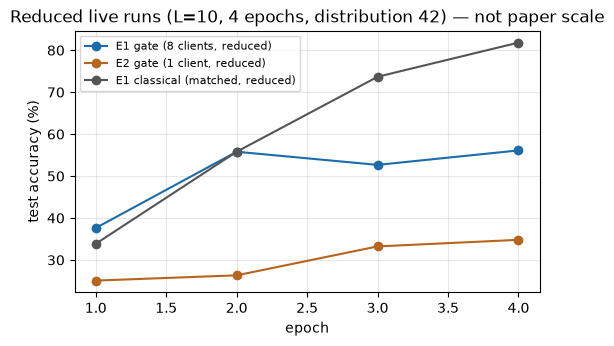

In [8]:
# Live results: test accuracy per epoch of the three reduced runs.
plt.figure(figsize=(6, 3.4))
for (label, metrics), color in zip(live.items(), ["#1b6ca8", "#b5651d", "#555555"]):
    plt.plot(range(1, LIVE_EPOCHS + 1), 100 * np.array(metrics["history"]["test_accuracy"]), "o-", color=color, label=label)
plt.xlabel("epoch"); plt.ylabel("test accuracy (%)"); plt.title("Reduced live runs (L=10, 4 epochs, distribution 42) — not paper scale")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

**Observation.** Even at reduced scale (printed above), 8 clients learn much faster and reach a much higher accuracy than one client. The classical model with the same number of parameters is clearly higher still after 4 epochs, and trains in under a second.

**Inference.** The pipeline works end to end, and the mechanism the paper describes (combining distinct feature slices) is visible. At this budget the classical model also learns faster per epoch.

**Remaining uncertainty.** Everything: one seed, a reduced circuit and 4 epochs.

**Claim impact.** None on its own. The paper-scale evidence follows.

## 7. Headline reproduction result (paper scale, stored)

**The runs.** The four experiments ran at the paper's settings ($L = 100$, 30 epochs), once per feature distribution, which is 20 runs of 16–35 minutes each.

**What is loaded.**
- **Values:** final-epoch test accuracies from `results/statistics.json`, generated by `utils/aggregate_results.py` from the validated sweep artifacts.
- **Curves:** per-epoch curves from `results/curves.json`.
- **Provenance:** the source sweep IDs are printed below. Each sweep's code state, configuration and environment are recorded in its `run_status.json` and in `LOG.md`. The environment was Python 3.11, torch 2.12.1, and an Apple M5 CPU.

In [9]:
# Stored: paper-scale results of E1-E4 (5 distributions each) and the authors' released values.
statistics = json.loads((RESULTS / "statistics.json").read_text())
curves = json.loads((RESULTS / "curves.json").read_text())
paper = {"E1": "over 94%", "E2": "below E1", "E3": "between E2 and E1", "E4": "about 90%"}
print(f"{'exp':<4} {'paper':<20} {'reproduced (final epoch)':<26} {'authors files':<16} per distribution (42..46)  [sweep]")
for exp in ["E1", "E2", "E3", "E4"]:
    e = statistics["experiments"][exp]
    f, a = e["final_epoch_test_accuracy"], e["authors_final_epoch"]
    values = " ".join(f"{100 * v:.1f}" for v in f["values"])
    print(f"{exp:<4} {paper[exp]:<20} {100 * f['mean']:.2f} +- {100 * f['std_ddof1']:.2f}{'':<12} {100 * a['mean']:.2f}{'':<10} {values}  [{curves[exp]['sweep_id']}]")

exp  paper                reproduced (final epoch)   authors files    per distribution (42..46)  [sweep]
E1   over 94%             92.85 +- 0.98             93.04           93.1 93.7 92.2 91.5 93.7  [e1_8clients_20261016-161327_e1]
E2   below E1             71.41 +- 2.48             70.03           71.2 70.8 74.9 72.1 68.0  [e2_1client_20261016-164104_e2]
E3   between E2 and E1    76.24 +- 3.50             76.30           78.7 74.0 79.0 78.4 71.2  [e3_8x1client_20261016-164705_e3]
E4   about 90%            90.60 +- 1.97             89.84           91.2 90.3 92.8 91.2 87.5  [e4_2x4clients_20261017-195148_e4]


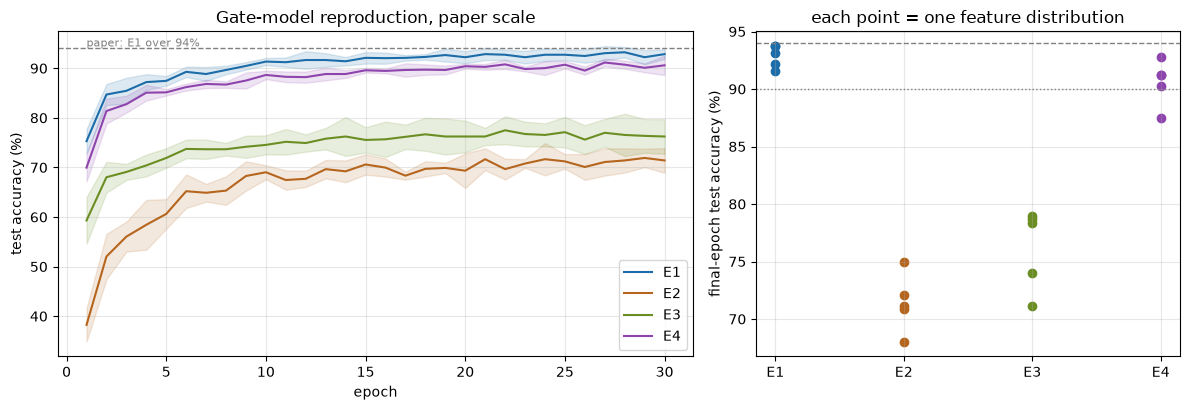

In [10]:
# Stored: test accuracy per epoch (mean +- std over the 5 distributions), and the final-epoch points.
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
for exp in ["E1", "E2", "E3", "E4"]:
    runs = np.array([curves[exp]["runs"][str(p)] for p in PERMUTATION_SEEDS]) * 100
    epochs = np.arange(1, runs.shape[1] + 1)
    left.plot(epochs, runs.mean(0), color=COLORS[exp], label=exp)
    left.fill_between(epochs, runs.mean(0) - runs.std(0, ddof=1), runs.mean(0) + runs.std(0, ddof=1), color=COLORS[exp], alpha=0.15)
    right.scatter(np.full(5, int(exp[1])), runs[:, -1], color=COLORS[exp])
left.axhline(94, color="grey", ls="--", lw=1); left.text(1, 94.4, "paper: E1 over 94%", fontsize=8, color="grey")
left.set(xlabel="epoch", ylabel="test accuracy (%)", title="Gate-model reproduction, paper scale"); left.legend(); left.grid(alpha=0.3)
right.axhline(94, color="grey", ls="--", lw=1); right.axhline(90, color="grey", ls=":", lw=1)
right.set(xticks=[1, 2, 3, 4], xticklabels=["E1", "E2", "E3", "E4"], ylabel="final-epoch test accuracy (%)", title="each point = one feature distribution")
right.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [11]:
# Which statistic is "over 94%"? Candidate readings computed from the stored per-epoch curves.
e1 = np.array([curves["E1"]["runs"][str(p)] for p in PERMUTATION_SEEDS])
print(f"final-epoch mean           {100 * e1[:, -1].mean():.2f}%")
print(f"peak of the mean curve     {100 * e1.mean(0).max():.2f}% (epoch {e1.mean(0).argmax() + 1}; selected on the test set)")
print(f"mean of per-run best epoch {100 * e1.max(1).mean():.2f}% (selected on the test set)")
print("authors' own files: final-epoch mean 93.04%, peak of the mean curve 94.04% (see LOG.md, ambiguity A1)")

final-epoch mean           92.85%
peak of the mean curve     93.23% (epoch 28; selected on the test set)
mean of per-run best epoch 93.92% (selected on the test set)
authors' own files: final-epoch mean 93.04%, peak of the mean curve 94.04% (see LOG.md, ambiguity A1)


**Observation.**
- **Means:** E1 = 92.85 ± 0.98%, E4 = 90.60 ± 1.97%, E3 = 76.24 ± 3.50% and E2 = 71.41 ± 2.48%.
- **Agreement with the authors:** each is within 1.4 points of the authors' own released final-epoch values.
- **The paper's "over 94%":** it is exceeded only by test-selected statistics. That is the peak of the mean curve in the authors' data (94.04%); ours peaks at 93.2%.

**Inference.**
- The paper's experiments reproduce **quantitatively against the authors' released results**.
- The ordering E1 > E4 > E3 > E2 reproduces.
- The headline ">94%" corresponds to a test-selected peak, not to the final-epoch protocol.

**Remaining uncertainty.** One training seed per distribution, and a 319-image test set.

**Claim impact:**
- C1 is **partially reproduced**: viability yes, ">94%" at the final epoch no.
- C4 ("about 90%") is reproduced.

## 8. Fair baseline comparison

**Why a new baseline is needed.**
- **Quantum controls only.** The paper's own baselines (E2–E4) are quantum ablations, and they are fair for C2–C4.
- **No classical comparator.** The paper has none, so its accuracy cannot be read as "good" or "useful" without one.

**The baseline.** A **classical vertical-FL model** with the same partitions (`lib/model_classical.py`):
- Each client is a one-hidden-layer ReLU MLP on its own 32 pixels, sending 8 tanh-bounded values, the same range as the gate model's ⟨Z⟩ messages.
- The server is a one-hidden-layer MLP producing 10 logits.

**The protocol.** The comparison plan was written in `LOG.md` before any baseline run.

| Fairness dimension | Gate model | Classical baseline | Matched? |
|---|---|---|---|
| Information and inputs | 32 pixels per client as angles {0, π/4}; 8-value message | the same pixels as binary {0, 1}, which is the same information; 8-value message | yes |
| Parameter count | 8000 per party, 72,000 for E1 | 8003 per client, 8035 server, 72,059 for E1 | yes (within 0.1%) |
| Training data | 1274 images, the same split and permutations | identical | yes |
| Optimisation steps | Adam, batch 32, 30 epochs | Adam, batch 32, 30 epochs | yes |
| Tuning budget | none (the paper's values) | learning rate chosen on a validation split from {0.001, 0.002, 0.005, 0.01} | **no**: favours the baseline slightly |
| Compute and wall time | about 1600 s per E1 run (simulated circuits) | about 2 s per E1 run | **no** (simulation cost; not compared) |
| Evaluation protocol | final-epoch test accuracy, 5 distributions | identical; 3 training seeds per distribution, seed 42 used for pairing | yes |

A centralised MLP on all 256 pixels (no federation) is shown as a reference, not as a competitor.

In [12]:
# Stored: Phase 5 comparison (generated by utils/compare_baselines.py from 225 classical runs and 60 quantum/photonic runs: 20 gate model, 40 photonic).
comparison = json.loads((RESULTS / "phase5_comparison.json").read_text())
rows = {(r["system"], r["layout"]): r for r in comparison["systems"]}
pairs = {(p["pair"], p["layout"]): p for p in comparison["pairs"]}
print(f"{'layout':<7} {'gate model':<16} {'classical matched':<18} {'difference':<11} {'positive in':<12} verdict (pre-declared rule)")
for layout in ["E1", "E2", "E3", "E4"]:
    q, c, p = rows[("gate", layout)], rows[("classical_gate", layout)], pairs[("gate - classical_gate", layout)]
    print(f"{layout:<7} {100 * q['mean_seed42']:.2f} +- {100 * q['std_seed42']:.2f}   {100 * c['mean_seed42']:.2f} +- {100 * c['std_seed42']:.2f}     "
          f"{100 * p['mean_difference']:+.2f}      {p['positive_in']}/5          {p['verdict']}")
coverage = comparison["coverage"]
print("sweep coverage: " + ", ".join(f"{c['system']} {c['completed']}/{c['expected']}" for c in coverage[:4]) + " ... "
      f"(all {sum(c['completed'] for c in coverage)}/{sum(c['expected'] for c in coverage)} runs completed and validated)")
central = rows[("classical_central:gate", "central")]
print(f"centralised MLP reference (72k params, all pixels): {100 * central['mean_seed42']:.2f} +- {100 * central['std_seed42']:.2f}")

layout  gate model       classical matched  difference  positive in  verdict (pre-declared rule)
E1      92.85 +- 0.98   93.61 +- 0.79     -0.75      0/5          no clear difference
E2      71.41 +- 2.48   75.42 +- 4.05     -4.01      0/5          no clear difference
E3      76.24 +- 3.50   77.74 +- 3.81     -1.50      0/5          no clear difference
E4      90.60 +- 1.97   91.97 +- 0.57     -1.38      1/5          no clear difference
sweep coverage: gate 5/5, gate 5/5, gate 5/5, gate 5/5 ... (all 285/285 runs completed and validated)
centralised MLP reference (72k params, all pixels): 93.29 +- 0.72


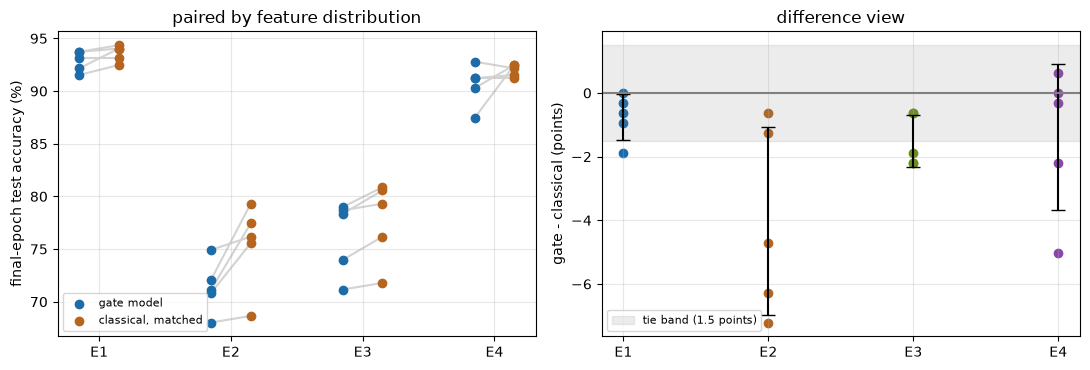

In [13]:
# Stored: individual results per distribution, quantum vs classical, with the paired differences.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for i, layout in enumerate(["E1", "E2", "E3", "E4"]):
    q = [100 * rows[("gate", layout)]["values_seed42"][str(p)] for p in PERMUTATION_SEEDS]
    c = [100 * rows[("classical_gate", layout)]["values_seed42"][str(p)] for p in PERMUTATION_SEEDS]
    for a, b in zip(q, c):
        axes[0].plot([i - 0.15, i + 0.15], [a, b], color="lightgrey", zorder=1)
    axes[0].scatter(np.full(5, i - 0.15), q, color="#1b6ca8", zorder=2, label="gate model" if i == 0 else None)
    axes[0].scatter(np.full(5, i + 0.15), c, color="#b5651d", zorder=2, label="classical, matched" if i == 0 else None)
    diffs = 100 * np.array(pairs[("gate - classical_gate", layout)]["differences"])
    axes[1].scatter(np.full(5, i), diffs, color=COLORS[layout])
    axes[1].errorbar(i, diffs.mean(), yerr=diffs.std(ddof=1), color="black", capsize=5)
axes[0].set(xticks=range(4), xticklabels=["E1", "E2", "E3", "E4"], ylabel="final-epoch test accuracy (%)", title="paired by feature distribution")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[1].axhline(0, color="grey"); axes[1].axhspan(-1.5, 1.5, color="grey", alpha=0.15, label="tie band (1.5 points)")
axes[1].set(xticks=range(4), xticklabels=["E1", "E2", "E3", "E4"], ylabel="gate - classical (points)", title="difference view"); axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3); plt.tight_layout(); plt.show()

**Observation.**
- **E1:** the gate model reaches 92.85% and the parameter-matched classical model 93.61%. The difference is −0.75 points, the quantum model is higher in 0 of 5 distributions, and p = 0.08.
- **Other layouts:** the classical model is numerically ahead in every layout, by 1.4–4.0 points. Each gap is within the larger of the two standard deviations, so by the pre-declared rule there is **no clear difference**.

**Inference.** The quantum model gives **no measurable accuracy benefit** over a classical vertical-FL model of the same size. The paper does not claim one, but this is the comparison that decides whether VQFL is useful.

**Remaining uncertainty:**
- one quantum seed per distribution;
- the baseline had a small learning-rate search;
- only one dataset.

**Claim impact.** VQFL is **viable** (on par with a matched classical model). There is no evidence of a quantum advantage.

## 9. Controls and ablations

**C2 and C3 controls.** The paper's own controls separate two explanations for E1's success:
- **(a)** combining *distinct* features;
- **(b)** a server that simply receives a *wider* input.

E3 keeps (b) but removes (a), by duplicating one slice over 8 clients.

**Generality check.** The same controls were run on the classical baseline. If the pattern is identical there, it is a property of vertical FL, not of quantum circuits.

**Loss control.** The authors' code applies softmax before cross-entropy (a double softmax), whereas the paper speaks of logits. E1 was re-run without the softmax.

In [14]:
# Stored: paired ablation differences (same distribution), quantum vs classical, and the loss control.
def paired(system, a, b):
    va, vb = rows[(system, a)]["values_seed42"], rows[(system, b)]["values_seed42"]
    d = np.array([va[str(p)] - vb[str(p)] for p in PERMUTATION_SEEDS]) * 100
    return d.mean(), d.std(ddof=1), int((d > 0).sum())

print(f"{'difference':<10} {'claim':<34} {'gate model':<24} {'classical, matched':<24}")
for a, b, claim in [("E1", "E2", "C2: 8 clients vs 1"), ("E1", "E3", "C3: distinct vs duplicated"), ("E3", "E2", "C3: wider server alone"), ("E1", "E4", "C4: all vs half the pixels")]:
    qm, qs, qn = paired("gate", a, b); cm, cs, cn = paired("classical_gate", a, b)
    print(f"{a}-{b:<7} {claim:<34} {qm:+6.2f} +- {qs:4.2f} ({qn}/5)     {cm:+6.2f} +- {cs:4.2f} ({cn}/5)")
# Loss control S5: E1 without the softmax before cross-entropy (final-epoch values from results/curves.json).
with_softmax = np.array([curves["E1"]["runs"][str(p)][-1] for p in PERMUTATION_SEEDS]) * 100
without_softmax = np.array([curves["E1_logits"]["runs"][str(p)][-1] for p in PERMUTATION_SEEDS]) * 100
d = without_softmax - with_softmax
print(f"\nloss control [{curves['E1_logits']['sweep_id']}]: without softmax {without_softmax.mean():.2f} +- {without_softmax.std(ddof=1):.2f}% "
      f"vs with {with_softmax.mean():.2f} +- {with_softmax.std(ddof=1):.2f}%; paired difference {d.mean():+.2f} +- {d.std(ddof=1):.2f} points ({int((d > 0).sum())}/5 positive)")

difference claim                              gate model               classical, matched      
E1-E2      C2: 8 clients vs 1                 +21.44 +- 3.25 (5/5)     +18.18 +- 4.58 (5/5)
E1-E3      C3: distinct vs duplicated         +16.61 +- 4.30 (5/5)     +15.86 +- 4.28 (5/5)
E3-E2      C3: wider server alone              +4.83 +- 1.98 (5/5)      +2.32 +- 1.62 (5/5)
E1-E4      C4: all vs half the pixels          +2.26 +- 2.73 (4/5)      +1.63 +- 0.26 (5/5)

loss control [e1_8clients_logits_control_20261019-083327_s5]: without softmax 92.85 +- 0.34% vs with 92.85 +- 0.98%; paired difference -0.00 +- 0.83 points (2/5 positive)


**Observation.**
- **E1 vs E2:** E1 beats E2 by 21 points in all 5 distributions.
- **E1 vs E3:** E1 beats E3 by 17 points in all 5.
- **E3 vs E2:** a wider server input alone (E3) adds only about 5 points.
- **Classical baseline:** it shows the **same pattern**, with +18, +16, +2 and +2 points.
- **Loss choice:** removing the double softmax changes nothing.

**Inference.**
- The paper's explanation survives its own control: distinct features, not server width, drive the gain.
- That explanation is equally true of a classical vertical-FL model, so it is **not a quantum effect**.

**Remaining uncertainty.** n = 5 per comparison, so p-values are indicative only.

**Claim impact.** **C2, C3 and C4 are reproduced.** They describe vertical FL in general.

## 10. Robustness and uncertainty

**C5: are results robust to the random feature assignment?** The paper shows a variance band over 5 distributions. The table below gives the spread over distributions for every system, together with the classical baseline's spread over its 3 training seeds. That second spread shows how much of the variation comes from initialisation rather than from the feature assignment.

In [15]:
# Stored: spread over distributions (seed 42) and over all classical training seeds.
print(f"{'system':<22} {'layout':<6} {'std over 5 distributions':<26} {'classical: mean over 3 seeds'}")
for layout in ["E1", "E2", "E3", "E4"]:
    for system in ["gate", "classical_gate"]:
        r = rows[(system, layout)]
        extra = f"{100 * r['mean_all_seeds']:.2f} +- {100 * r['std_all_seeds']:.2f}" if system.startswith("classical") else "1 seed per distribution"
        print(f"{system:<22} {layout:<6} {100 * r['std_seed42']:.2f} points{'':<15} {extra}")

system                 layout std over 5 distributions   classical: mean over 3 seeds
gate                   E1     0.98 points                1 seed per distribution
classical_gate         E1     0.79 points                93.06 +- 0.60
gate                   E2     2.48 points                1 seed per distribution
classical_gate         E2     4.05 points                75.49 +- 3.18
gate                   E3     3.50 points                1 seed per distribution
classical_gate         E3     3.81 points                77.39 +- 3.30
gate                   E4     1.97 points                1 seed per distribution
classical_gate         E4     0.57 points                91.89 +- 0.48


**Observation.**
- **Spread over distributions:** 1–4 points, smallest for E1 and E4 and largest when only one slice of pixels is used (E2, E3).
- **Classical seeds:** for the gate-matched classical model shown here, averaging over 3 training seeds moves its means by at most 0.6 points (at most 1.7 points across all baseline sizes; see `results/phase5_comparison.md`).

**Inference.** Results are robust to the random feature assignment at the level the paper claims (C5). Differences under about 1.5–2 points, about 5 test images, are not interpretable.

**Remaining uncertainty.** Initialisation variance of the gate model is not separated, because it has one seed per distribution.

**Claim impact.** **C5 is reproduced.**

## 11. Photonic assessment (MerLin adaptation)

**Question.** Does the paper's vertical-FL structure carry over to photonic hardware, simulated with MerLin? This is an **adaptation**: it preserves the scientific role, not the gate circuit.

**Architecture.** Every party is one photonic chip with 8 modes and 4 photons, input $|1,0,1,0,1,0,1,0\rangle$. It alternates trainable interferometer meshes with phase encodings of 8 inputs, which is data re-uploading.

**Final designs.** These were found with validation-only diagnostics, whose full tables are in `results/selection_sweeps.md`.
- **H:** clients send mean photon numbers, and the server reads out through a small trainable linear head (410 classical parameters) on its per-mode photon-number distributions.
- **F (fully photonic):** clients send click probabilities, which is what threshold detectors report, and the server groups its 330 output patterns into 10 classes.

**Settings.** Both designs use MerLin's `FOCK` space: photon-number-resolving detection with no post-selection, an exact simulator, no noise and no shots.

The live cell first shows a physics subtlety that shaped the design.

In [16]:
# Live: Hong-Ou-Mandel probe. Input |1,1>, 50:50 splitter, phase x on mode 0, 50:50 splitter.
import merlin as ml
import perceval as pcvl

circuit = pcvl.Circuit(2); circuit.add(0, pcvl.BS()); circuit.add(0, pcvl.PS(pcvl.P("px1"))); circuit.add(0, pcvl.BS())
xs = torch.tensor([[0.0], [0.5], [1.0], [1.5]])
for space in (ml.ComputationSpace.UNBUNCHED, ml.ComputationSpace.FOCK):
    layer = ml.QuantumLayer(input_size=1, circuit=circuit, input_parameters=["px"], trainable_parameters=[], input_state=[1, 1], n_photons=2,
                            measurement_strategy=ml.MeasurementStrategy.probs(computation_space=space))
    print(f"{space.name:<9} outcomes {list(layer.output_keys)}  P = {layer(xs).detach().numpy().round(3).tolist()}")
print("exact P(1,1) = cos^2(x):", [round(math.cos(v) ** 2, 3) for v in xs.squeeze().tolist()])

UNBUNCHED outcomes [(1, 1)]  P = [[1.0], [1.0], [1.0], [1.0]]
FOCK      outcomes [(2, 0), (1, 1), (0, 2)]  P = [[0.0, 1.0, 0.0], [0.11500000208616257, 0.7699999809265137, 0.11500000208616257], [0.3540000021457672, 0.2919999957084656, 0.3540000021457672], [0.4970000088214874, 0.004999999888241291, 0.4970000088214874]]
exact P(1,1) = cos^2(x): [1.0, 0.77, 0.292, 0.005]


**Observation.** `UNBUNCHED` keeps only collision-free outcomes and renormalises them. Here that leaves a single outcome with probability 1 for every input. `FOCK` returns the exact cos²(x).

**Inference.** `UNBUNCHED` is **post-selection**, not threshold detection. This is why the final designs use `FOCK` and report post-selection explicitly. This item is also sent to the MerLin team (`ACTION_REQUIRED_SEND_TO_MERLIN_TEAM.md`).

In [17]:
# Live (about 1 min): a reduced photonic run (design H, 5 epochs instead of 100, full data, distribution 42) through the same runner.
photonic_config = json.loads((PROJECT_DIR / "configs/e1_8clients_merlin_head.json").read_text())
PHOTONIC_LIVE_EPOCHS = 5
photonic_live = run_live(photonic_config, {"training": {"epochs": PHOTONIC_LIVE_EPOCHS}}, "E1 photonic H (reduced: 5 epochs)")
print("test accuracy per epoch:", [round(v, 3) for v in photonic_live["history"]["test_accuracy"]])
paper_scale = np.array([curves["E1h"]["runs"][str(p)] for p in PERMUTATION_SEEDS])
print("paper-scale design H at the same epochs (mean of 5 distributions, stored):", np.round(paper_scale.mean(0)[:PHOTONIC_LIVE_EPOCHS], 3).tolist())
print("photonic parameters:", photonic_live["trainable_parameters"])

E1 photonic H (reduced: 5 epochs)  params   3154  test acc 0.636  (79 s)
test accuracy per epoch: [0.389, 0.414, 0.549, 0.524, 0.636]
paper-scale design H at the same epochs (mean of 5 distributions, stored): [0.329, 0.427, 0.517, 0.512, 0.617]
photonic parameters: {'client_0': 280, 'client_1': 280, 'client_2': 280, 'client_3': 280, 'client_4': 280, 'client_5': 280, 'client_6': 280, 'client_7': 280, 'server': 914, 'server_classical_head': 410, 'total': 3154}


**Observation.** The live reduced run (5 of 100 epochs, distribution 42) follows the stored paper-scale learning curve of design H closely over the same epochs, as printed above.

**Inference.** The stored photonic results come from the same pipeline that runs here. **Remaining uncertainty:** this is one seed and the first 5 epochs only.

layout | gate | photonic_h | classical_photonic_h | photonic_f | classical_photonic_f
E1     | 92.85 +- 0.98 | 86.83 +- 1.77 | 89.97 +- 0.59 | 76.87 +- 3.15 | 88.53 +- 1.39
E2     | 71.41 +- 2.48 | 58.18 +- 5.85 | 68.28 +- 2.12 | 48.28 +- 3.36 | 65.89 +- 2.14
E3     | 76.24 +- 3.50 | 64.39 +- 3.09 | 73.48 +- 3.54 | 61.07 +- 3.74 | 72.29 +- 4.97
E4     | 90.60 +- 1.97 | 81.13 +- 4.05 | 88.59 +- 1.95 | 75.05 +- 4.03 | 84.83 +- 2.01

parameters (E1): {'gate': 72000, 'photonic_h': 3154, 'classical_photonic_h': 3270, 'photonic_f': 2744, 'classical_photonic_f': 2895}


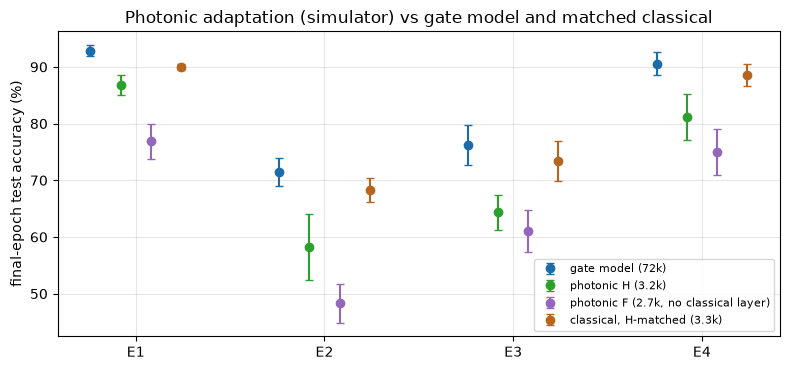

In [18]:
# Stored: paper-scale photonic results (5 distributions each) next to the gate model and the matched classical baselines.
systems = ["gate", "photonic_h", "classical_photonic_h", "photonic_f", "classical_photonic_f"]
print("layout | " + " | ".join(systems))
for layout in ["E1", "E2", "E3", "E4"]:
    print(f"{layout:<6} | " + " | ".join(f"{100 * rows[(s, layout)]['mean_seed42']:.2f} +- {100 * rows[(s, layout)]['std_seed42']:.2f}" for s in systems))
print("\nparameters (E1):", {s: rows[(s, 'E1')]["parameters_total"] for s in ["gate", "photonic_h", "classical_photonic_h", "photonic_f", "classical_photonic_f"]})

fig, ax = plt.subplots(figsize=(8, 3.8))
for offset, system, color, label in [(-0.24, "gate", "#1b6ca8", "gate model (72k)"), (-0.08, "photonic_h", "#2ca02c", "photonic H (3.2k)"),
                                     (0.08, "photonic_f", "#9467bd", "photonic F (2.7k, no classical layer)"), (0.24, "classical_photonic_h", "#b5651d", "classical, H-matched (3.3k)")]:
    means = [100 * rows[(system, l)]["mean_seed42"] for l in ["E1", "E2", "E3", "E4"]]
    stds = [100 * rows[(system, l)]["std_seed42"] for l in ["E1", "E2", "E3", "E4"]]
    ax.errorbar(np.arange(4) + offset, means, yerr=stds, fmt="o", color=color, capsize=3, label=label)
ax.set(xticks=range(4), xticklabels=["E1", "E2", "E3", "E4"], ylabel="final-epoch test accuracy (%)", title="Photonic adaptation (simulator) vs gate model and matched classical")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

**Observation:**
- **Comparative structure preserved in both designs.** E1 beats E2 and E3 in 5/5 distributions, and E4 beats E3 in 5/5; these criteria were declared before the runs.
- **Accuracy.** At E1, design H reaches 86.83% and the fully photonic F 76.87%.
- **Below the matched classical baselines everywhere,** by 3–10 points for H and 10–18 points for F.

**Inference.** The vertical-FL structure maps meaningfully to MerLin photonic chips and behaves qualitatively like the paper.

**Remaining uncertainty:**
- designs were tuned on E1 only, with 2 seeds;
- simulator only, and `FOCK` assumes photon-number-resolving detectors;
- curves oscillate by about ±5 points between epochs.

**Claim impact:**
- Photonic verdict: `MERLIN_IMPLEMENTATION`, qualitative behaviour reproduced.
- There is **no evidence of a photonic advantage** at this scale.

## 12. Claim-level conclusion

**1. What reproduced:**
- All four experiments agree with the authors' released results to within 1.4 points (§7).
- C2: 8 clients beat 1 client by 21 points in 5/5 distributions (§9).
- C3: distinct features, not server width, drive the gain (§9).
- C4: half the pixels reaches 90.6%, only slightly below E1 (§7, §9).
- C5: robust across feature distributions (§10).
- The split and the authors' trained model reproduce exactly (§2, §4).

**2. What did not reproduce:**
- The paper's "over 94%" at the final epoch. We get 92.85%, and the authors' own files give 93.04%. 94% is reached only as the test-selected peak of the authors' mean curve (§7).

**3. What remains unresolved:**
- The initialisation variance of the gate model, since there is one seed per distribution (§10).
- Whether the photonic gap to the classical baseline is due to capacity or to training budget and tuning (§11).

**4. What was not attempted:**
- The privacy claim (no attack model) and NISQ suitability (no noise model or QPU run).
- Other datasets.

**5. Reproduction verdict: partially reproduced.**
- The paper's comparative claims (C2–C5) are reproduced. The headline number (C1) holds only as a test-selected peak.
- Against a parameter-matched classical vertical-FL model there is **no clear difference and no quantum advantage** (§8). The same ablation pattern appears classically, so the paper's findings are properties of vertical FL, not quantum effects (§9).

**6. Photonic verdict: `MERLIN_IMPLEMENTATION`, qualitative structure reproduced.**
- The MerLin adaptation preserves the paper's comparative structure in both designs, with best accuracy 86.83% (H) and 76.87% fully photonic (F).
- It is below its parameter-matched classical baselines in every layout, so there is no photonic advantage at this scale (§11).

**Separating the outcomes:**
- **The software executes:** yes (§4–§6).
- **The method solves the task:** yes, about 93% on 10 classes (§7).
- **The paper's metric reproduces:** partly; ">94%" does not at the final epoch (§7).
- **The paper's explanation survives controls:** yes, but it is not specific to quantum models (§9).
- **The method beats a fair baseline:** no (§8).